## Download evaluation results

In [1]:
import pandas as pd

res = pd.read_csv('../UniPert/results/chemical_perturbation_sciplex_HDAC_results.csv')
res = res.drop_duplicates()
res

,model,dataset,split_key,cell_type,condition,dose,n_top_deg,r2_mean_deg,mse_mean_deg,pcc_mean_deg,ccc_mean_deg
0,UniMol,sciplex3_HDAC,loo_split_6,MCF7,Dacinostat,0.1,10,0.152816,0.933012,0.717699,0.559915
1,UniMol_noPerturb,sciplex3_HDAC,loo_split_6,MCF7,Dacinostat,0.1,10,-0.419671,1.563497,0.383121,0.255507
2,UniMol,sciplex3_HDAC,loo_split_6,MCF7,Dacinostat,0.1,20,0.279502,0.592238,0.716879,0.584055
3,UniMol_noPerturb,sciplex3_HDAC,loo_split_6,MCF7,Dacinostat,0.1,20,-0.213317,0.997328,0.352309,0.273763
4,UniMol,sciplex3_HDAC,loo_split_6,MCF7,Dacinostat,0.1,50,0.394828,0.303658,0.723005,0.612473
...,...,...,...,...,...,...,...,...,...,...,...
163195,KPGT_noPerturb,sciplex3_HDAC,loo_split_3,K562,Panobinostat,0.1,20,-32.892357,0.177794,0.865342,0.183468
163196,KPGT,sciplex3_HDAC,loo_split_3,K562,Panobinostat,0.1,50,-2.258998,0.074262,0.289515,0.201029
163197,KPGT_noPerturb,sciplex3_HDAC,loo_split_3,K562,Panobinostat,0.1,50,-4.337971,0.121635,0.217777,0.125790
163198,KPGT,sciplex3_HDAC,loo_split_3,K562,Panobinostat,0.1,all,0.765807,0.003857,0.879693,0.878532


In [2]:
res['dataset'].value_counts()

dataset
sciplex3_HDAC    163200
Name: count, dtype: int64

In [3]:
res[['split_key', 'condition']].value_counts().sort_index()

split_key     condition   
loo_split_1   Belinostat      9600
loo_split_10  Givinostat      9600
loo_split_11  Tacedinaline    9600
loo_split_12  CUDC-907        9600
loo_split_13  M344            9600
loo_split_14  Resminostat     9600
loo_split_15  Entinostat      9600
loo_split_16  CUDC-101        9600
loo_split_17  Trichostatin    9600
loo_split_2   Mocetinostat    9600
loo_split_3   Panobinostat    9600
loo_split_4   Abexinostat     9600
loo_split_5   Pracinostat     9600
loo_split_6   Dacinostat      9600
loo_split_7   Quisinostat     9600
loo_split_8   Tucidinostat    9600
loo_split_9   AR-42           9600
Name: count, dtype: int64

In [4]:
res['model'].value_counts()

model
UniMol               20400
UniMol_noPerturb     20400
chemCPA              20400
chemCPA_noPerturb    20400
UniPert              20400
UniPert_noPerturb    20400
KPGT                 20400
KPGT_noPerturb       20400
Name: count, dtype: int64

In [5]:
res[res['n_top_deg']=='all'].groupby(['model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean()


,r2_mean_deg,pcc_mean_deg,ccc_mean_deg,mse_mean_deg
model,,,,
KPGT,0.904178,0.954055,0.948389,0.001716
KPGT_noPerturb,0.850126,0.924400,0.922262,0.002684
UniMol,0.893616,0.948245,0.944780,0.001901
UniMol_noPerturb,0.850126,0.924400,0.922262,0.002684
UniPert,0.907437,0.957196,0.951327,0.001656
UniPert_noPerturb,0.850126,0.924400,0.922262,0.002684
chemCPA,0.870604,0.935362,0.931660,0.002323
chemCPA_noPerturb,0.850126,0.924400,0.922262,0.002684


In [6]:
res[res['n_top_deg']=='20'].groupby(['model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean()


,r2_mean_deg,pcc_mean_deg,ccc_mean_deg,mse_mean_deg
model,,,,
KPGT,-1.806868,0.864645,0.796309,0.122805
KPGT_noPerturb,-3.995105,0.756873,0.687719,0.226434
UniMol,-2.046480,0.851647,0.793545,0.128544
UniMol_noPerturb,-3.995105,0.756873,0.687719,0.226434
UniPert,-0.490534,0.896207,0.846988,0.093125
UniPert_noPerturb,-3.995105,0.756873,0.687719,0.226434
chemCPA,-3.298176,0.796464,0.726693,0.188746
chemCPA_noPerturb,-3.995105,0.756873,0.687719,0.226434


In [7]:
res['model'] = res['model'].replace({
    'chemCPA_noPerturb': 'No Perturb',
    'chemCPA': 'chemCPA',
    'UniMol': 'Uni-Mol'
})
models= ['No Perturb', 'chemCPA', 'Uni-Mol', 'KPGT', 'UniPert']
res = res[res['model'].isin(models)]
res['rank'] = res['model'].apply(lambda x: models.index(x))
res = res.sort_values(by='rank')

/tmp/ipykernel_3733232/2323043911.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  res['rank'] = res['model'].apply(lambda x: models.index(x))


###  overall 

In [8]:
res.groupby(['model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean().reindex(models)

,r2_mean_deg,pcc_mean_deg,ccc_mean_deg,mse_mean_deg
model,,,,
No Perturb,-2.273543,0.794899,0.742743,0.170941
chemCPA,-1.813562,0.826143,0.775122,0.142408
Uni-Mol,-1.028858,0.870281,0.829304,0.096188
KPGT,-0.812334,0.881242,0.831742,0.092887
UniPert,-0.000462,0.907737,0.872727,0.069080


###  by cell line

In [9]:
res.groupby(['cell_type', 'model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean()

r2_mean_deg  pcc_mean_deg  ccc_mean_deg  mse_mean_deg
cell_type model                                                            
A549      KPGT           0.813771      0.908972      0.882479      0.099801
          No Perturb     0.664473      0.819526      0.784423      0.183549
          Uni-Mol        0.812865      0.906058      0.886375      0.096640
          UniPert        0.875491      0.942684      0.928248      0.059434
          chemCPA        0.715055      0.852754      0.818535      0.155022
K562      KPGT          -4.048306      0.828038      0.743405      0.046958
          No Perturb    -8.121619      0.763424      0.667224      0.090468
          Uni-Mol       -4.683258      0.810259      0.732853      0.050769
          UniPert       -1.689089      0.871425      0.805651      0.026844
          chemCPA       -6.872020      0.775493      0.681190      0.081913
MCF7      KPGT           0.797534      0.906717      0.869342      0.131902
          No Perturb     0.636518      0.801747      0.776582      0.238805
          Uni-Mol        0.783820      0.894526      0.868683      0.141156
          UniPert        0.812213      0.909102      0.884283      0.120963
          chemCPA        0.716280      0.850181      0.825640      0.190290

###  by condition

In [20]:
conditions = res[(res['model'].isin(['No Perturb'])) & (res['n_top_deg']=='all')]\
    .groupby(['condition'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']]\
    .mean()\
    .sort_values(by='pcc_mean_deg')\
    .index.to_list()[:10]
conditions

['Panobinostat',
 'Quisinostat',
 'Dacinostat',
 'Abexinostat',
 'AR-42',
 'CUDC-907',
 'Pracinostat',
 'Belinostat',
 'Givinostat',
 'Mocetinostat']

In [21]:
res[(res['n_top_deg']=='all') & (res['condition'].isin(conditions))].\
    groupby(['model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].\
    mean()\
    .sort_values(by='pcc_mean_deg', ascending=False)



,r2_mean_deg,pcc_mean_deg,ccc_mean_deg,mse_mean_deg
model,,,,
UniPert,0.875918,0.942399,0.934850,0.002232
KPGT,0.859947,0.932242,0.924341,0.002520
Uni-Mol,0.848729,0.926220,0.921451,0.002721
chemCPA,0.806926,0.902226,0.898282,0.003478
No Perturb,0.776779,0.887165,0.884173,0.004009


In [22]:
res[(res['n_top_deg']=='20') & (res['condition'].isin(conditions))]\
    .groupby(['model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']]\
    .mean()\
    .sort_values(by='pcc_mean_deg', ascending=False)

,r2_mean_deg,pcc_mean_deg,ccc_mean_deg,mse_mean_deg
model,,,,
UniPert,-1.482839,0.839637,0.763101,0.144978
KPGT,-3.727553,0.786445,0.677965,0.195837
Uni-Mol,-4.127545,0.768228,0.673846,0.204331
chemCPA,-6.232629,0.683637,0.575296,0.300190
No Perturb,-7.393763,0.626806,0.519811,0.358144


## Plot

In [14]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns

font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.5,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]   
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"

print(f"✅ Loaded custom font: {font_name}")

✅ Loaded custom font: Helvetica


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


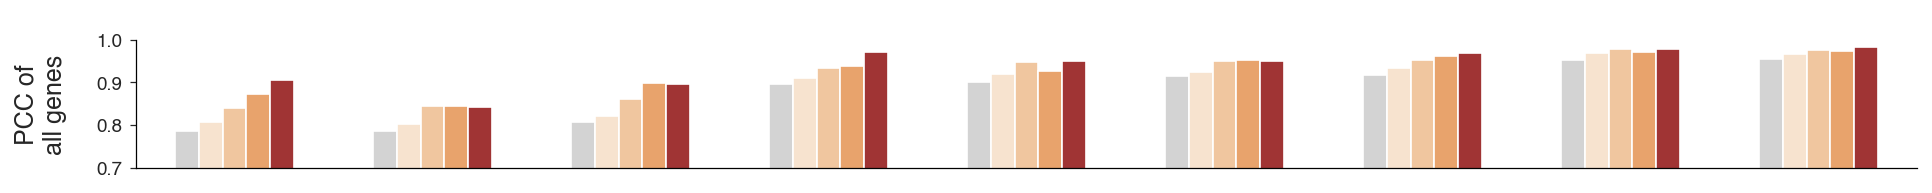

In [15]:
data = res[(res['model'].isin(models)) & (res['n_top_deg']=='all') & (res['condition'].isin(conditions[:9]))]\
    .groupby(['condition', 'model'])[['pcc_mean_deg']]\
    .mean()\
    .reset_index()

model_order = {model: i for i, model in enumerate(models)}
condition_order = {condition: i for i, condition in enumerate(conditions[:10])}

data['model_order'] = data['model'].map(model_order)
data['condition_order'] = data['condition'].map(condition_order)

data = data.sort_values(['condition_order', 'model_order'])

plt.figure(figsize=(13, 1.5))
palette = ['lightgray'] + sns.color_palette('Oranges')[:3] + ['firebrick']

ax = sns.barplot(
    data=data, 
    x="condition", 
    y="pcc_mean_deg", 
    hue="model",
    errorbar="sd", 
    palette=palette,
    gap=0,
    width=0.6,
    legend=False,
)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(0.6)
ax.spines['bottom'].set_linewidth(0.6)

ax.tick_params(axis='both', which='major', width=0.6, length=3)
ax.tick_params(axis='x', which='major', width=0.6, color='white')

ax.set_ylim(0.7, 1)
ax.set_yticks([0.7, 0.8, 0.9, 1])
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
ax.set_xticks([])
ax.set_xlabel('')
ax.set_ylabel('PCC of\nall genes', fontsize=12, labelpad=14)
plt.legend(bbox_to_anchor=(0.5, 1.3), fontsize=12, facecolor='white', ncol=6, 
           loc='upper center', frameon=False)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3733232/2113550672.py:37: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


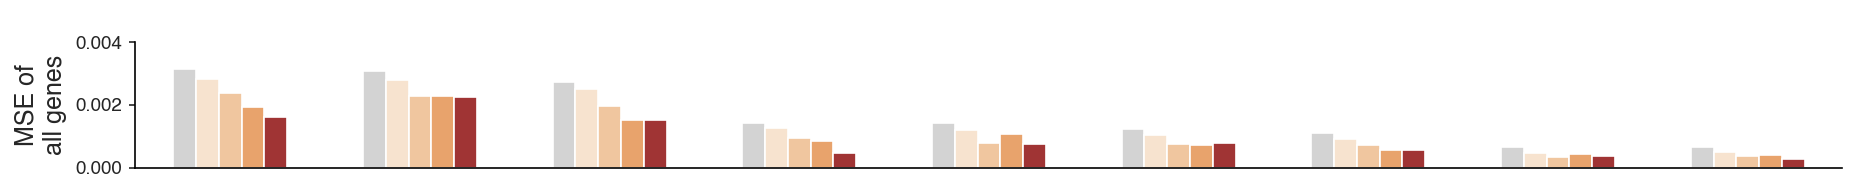

In [19]:

data = res[(res['model'].isin(models)) & (res['n_top_deg']=='all') & (res['condition'].isin(conditions[:9]))]\
    .groupby(['condition', 'model'])[['mse_mean_deg']]\
    .mean()\
    .reset_index()

model_order = {model: i for i, model in enumerate(models)}
condition_order = {condition: i for i, condition in enumerate(conditions[:9])}

data['model_order'] = data['model'].map(model_order)
data['condition_order'] = data['condition'].map(condition_order)

data = data.sort_values(['condition_order', 'model_order'])

plt.figure(figsize=(12.5, 1.5))
palette = ['lightgray'] + sns.color_palette('Oranges')[:3] + ['firebrick']
ax = sns.barplot(
    data=data, 
    x="condition", 
    y="mse_mean_deg", 
    hue="model",
    errorbar="sd", 
    palette=palette,
    gap=0,
    width=0.6,
    legend=False,
)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

ax.tick_params(axis='both', which='major', width=0.8, length=3)
ax.tick_params(axis='x', which='major', width=0.8, color='white')

ax.set_ylim(0.0, 0.01)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
ax.set_xticks([])
ax.set_xlabel('')
ax.set_ylabel('MSE of\nall genes', fontsize=12)
plt.legend(bbox_to_anchor=(0.5, 1.3), fontsize=10, facecolor='white', ncol=6, 
           loc='upper center', frameon=False)
           
plt.tight_layout()
plt.show()

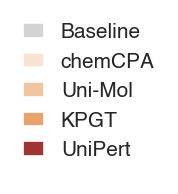

In [17]:
data = res[(res['model'].isin(models)) & (res['n_top_deg']=='all') & (res['condition'].isin(conditions[:9]))]\
    .groupby(['condition', 'model'])[['mse_mean_deg']]\
    .mean()\
    .reset_index()

model_order = {model: i for i, model in enumerate(models)}
condition_order = {condition: i for i, condition in enumerate(conditions[:9])}

data['model_order'] = data['model'].map(model_order)
data['condition_order'] = data['condition'].map(condition_order)
data['model'] = data['model'].replace({'No Perturb': 'Baseline'})

data = data.sort_values(['condition_order', 'model_order'])

plt.figure(figsize=(1, 1.5))
palette = ['lightgray'] + sns.color_palette('Oranges')[:3] + ['firebrick']
ax = sns.barplot(
    data=data, 
    x="condition", 
    y="mse_mean_deg", 
    hue="model",
    errorbar="sd", 
    palette=palette,
    gap=0.15,
    width=0.6,
    legend=True,
)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(0)
ax.spines['bottom'].set_linewidth(0)
ax.tick_params(axis='both', which='major', width=0, length=3)

ax.set_ylim(0.0, 0.01)
ax.set_yticklabels([], fontsize=9)
ax.set_xticks([])
ax.set_xlabel('')
ax.set_ylabel('', fontsize=12)
plt.legend(bbox_to_anchor=(0.5, 1.3), 
           fontsize=10, 
           facecolor='white', 
           ncol=1, 
           loc='upper center', 
           handlelength=1
           )
plt.tight_layout()
plt.show()